# EECS E6893 — HW5 Complete Working Notebook (Q1 + Q2 + Q3)

**English integrated working version — November 19, 2026**

This Notebook contains Q1/Q2/Q3 sequence.

### How to run in a fresh Google Colab CPU runtime

1. Upload **both** `HW5_export.zip` (the unchanged CourseWorks starter) and `HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip` (the updated project code) in Cell 1. Do not upload the notebook itself via `files.upload()`; you already opened it in Colab.
2. Run the Notebook **from top to bottom**. The setup extracts the project and then imports the corrected modules.
3. The Spark chunking cell uses RDD `flatMap` rather than `mapInPandas` to avoid the Arrow/Java failure observed earlier. The following cell verifies the physical Parquet partitions.
4. The Q2 Gateway and additional timing experiments can take longer; do not confuse a still-running cell with a completed test.
5. Run the ZIP-export cell **before** `spark.stop()` to save the generated CSV/JSON/PNG files. Keep the resulting `.ipynb` file as well.

**Reporting:** All numbers must be taken from this fresh run, not previous screenshots. State the exact Colab hardware, warm-up and measured call counts. The defenses-off experiment only disables *answer-stage* guards; ingestion PII masking is still active in that arm. Do not report the development-set accuracy as held-out accuracy. Q3 curated label corrections are **not** a model improvement. Follow the course AI-assistance and citation policy.


In [1]:
from google.colab import files

uploaded = files.upload()

Saving HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip to HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip
Saving HW5_export.zip to HW5_export.zip


In [2]:
import os

print(os.listdir("/content"))

['.config', 'HW5_export.zip', 'HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip', 'sample_data']


In [3]:
from pathlib import Path
import os, sys, zipfile, shutil
IN_COLAB = 'google.colab' in sys.modules
course = Path('/content/course/hw5_starter') if IN_COLAB else Path.cwd().parent / 'hw5_starter'
project = Path('/content/work/HW5_Official_Integrated_Code') if IN_COLAB else Path.cwd()
if IN_COLAB:
    course_zip = Path('/content/HW5_export.zip')
    patch_zip = Path('/content/HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip')
    if not course.joinpath('hw5lib.py').exists():
        if not course_zip.exists():
            raise FileNotFoundError('Upload HW5_export.zip to /content first.')
        with zipfile.ZipFile(course_zip) as archive:
            archive.extractall('/content/course')
    if not patch_zip.exists():
        raise FileNotFoundError('Upload HW5_Q1_Q2_Q3_Integrated_Code_20261119.zip to /content first.')
    # Replace the old integration, not just reuse previously extracted modules.
    project.parent.mkdir(parents=True, exist_ok=True)
    if project.exists():
        shutil.rmtree(project)
    with zipfile.ZipFile(patch_zip) as archive:
        archive.extractall('/content/work')
if not (course / 'hw5lib.py').exists():
    raise FileNotFoundError('Course starter hw5lib.py is missing.')
if not (project / 'hw5_core.py').exists():
    raise FileNotFoundError('Patched hw5_core.py is missing.')
sys.path.insert(0,str(course));sys.path.insert(0,str(project))
os.environ['HW5_DATA_DIR'] = str(course / 'data')
os.chdir(course)
print('Course starter:',course)
print('Patched project:',project)


Course starter: /content/course/hw5_starter
Patched project: /content/work/HW5_Official_Integrated_Code


In [4]:
%pip -q install pyspark==3.5.3 pyarrow scikit-learn numpy pandas matplotlib
import os, re, json, time, hashlib, html, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_colwidth',120)
import hw5lib as H
from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.sql.window import Window
import importlib
import hw5_core, hw5_system as S
importlib.reload(hw5_core)
importlib.reload(S)
from hw5_core import (make_chunks, clean_html, pii_spans, mask_pii as core_mask,
                      SearchIndex, safe_answer, answer_with_citation_guard,
                      answer_retrieved_evidence, validate_answer_citations)
from production import TwoTierCache, Gateway, CircuitBreaker
JAVA_OPTS = '-Dio.netty.tryReflectionSetAccessible=true --add-opens=java.base/java.nio=ALL-UNNAMED --add-opens=java.base/sun.nio.ch=ALL-UNNAMED --add-opens=java.base/java.lang=ALL-UNNAMED'
spark=(SparkSession.builder.master('local[2]').appName('hw5_student_filled_draft')
       .config('spark.ui.enabled','false').config('spark.sql.shuffle.partitions','4')
       .config('spark.driver.extraJavaOptions',JAVA_OPTS).getOrCreate())
spark.sparkContext.setLogLevel('ERROR')
DEV=H.load_golden('dev');OUT=str(project/'outputs'/'student_todo');os.makedirs(OUT,exist_ok=True)
print('Hardware:',platform.platform(),'| logical CPUs:',os.cpu_count(),'| questions:',len(DEV))

# Verify active project version (avoid stale imports from a previous runtime).
assert (project/'q2_experiments.py').is_file()
assert (project/'q3'/'run.py').is_file()
print('Q2 additional experiments: included in this notebook')


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.3 which is incompatible.
Hardware: Linux-6.6.159+-x86_64-with-glibc2.39 | logical CPUs: 2 | questions: 66
Q2 additional experiments: included in this notebook


---
# Q1 · Knowledge Ingestion Pipeline (30 points)
## Problem 1 · Data contract and profiling (8 points)

### 1.1.1 Schema, validation rules and quarantine
Read `kb_articles.jsonl` and `tickets.csv` with **explicit schemas**. Write validation rules and send
every violating record to a quarantine table with the rule it broke. At minimum check: missing
`article_id`, empty body, impossible dates, invalid `status`/`category`, and duplicate
`(article_id, version)` keys. Decide what to do with exact duplicates vs. same-key-different-content
duplicates, and say why. Normalising a value (for example `" Active"`) is allowed if you document it.

In [5]:
ARTICLE_SCHEMA = T.StructType([
    T.StructField("article_id", T.StringType()), T.StructField("version", T.IntegerType()),
    T.StructField("title", T.StringType()), T.StructField("category", T.StringType()),
    T.StructField("body", T.StringType()), T.StructField("effective_date", T.StringType()),
    T.StructField("status", T.StringType()), T.StructField("source", T.StringType())])
raw_articles = spark.read.schema(ARTICLE_SCHEMA).json(os.path.join(H.DATA_DIR, "kb_articles.jsonl"))
TICKET_SCHEMA = T.StructType([T.StructField(c, T.StringType()) for c in
                              ["ticket_id", "created_at", "category", "customer_message", "agent_reply"]])
raw_tickets = (spark.read.option("header", True).option("multiLine", True).option("escape", '"')
               .schema(TICKET_SCHEMA).csv(os.path.join(H.DATA_DIR, "tickets.csv")))
print(raw_articles.count(), "article rows |", raw_tickets.count(), "ticket rows")

119 article rows | 2400 ticket rows


In [6]:
# Q1.1.1 - Named validation conditions and quarantine; duplicate keys are
# quarantined after the first deterministic source row, with a reason.
allowed_categories=['refund','shipping','product','account','other']
prepared=(raw_articles.withColumn('row_order',F.monotonically_increasing_id())
          .withColumn('status',F.lower(F.trim('status')))
          .withColumn('effective_dt',F.to_date('effective_date','yyyy-MM-dd')))
win=Window.partitionBy('article_id','version').orderBy('row_order')
prepared=(prepared.withColumn('row_number',F.row_number().over(win))
          .withColumn('first_content_hash',F.first(F.sha2(F.concat_ws('|',
              *[F.coalesce(F.col(c).cast('string'),F.lit('')) for c in ['title','category','body','effective_date','status','source']]),256)).over(win)))
hash_now=F.sha2(F.concat_ws('|',*[F.coalesce(F.col(c).cast('string'),F.lit(''))
                                  for c in ['title','category','body','effective_date','status','source']]),256)
violations=F.array(
    F.when(F.col('article_id').isNull() | (F.trim('article_id')==''),'missing_article_id'),
    F.when(F.col('version').isNull(),'missing_version'),
    F.when(F.col('body').isNull() | (F.trim('body')==''),'empty_body'),
    F.when(F.col('effective_dt').isNull(),'invalid_date'),
    F.when(~F.col('status').isin('active','retired','draft'),'invalid_status'),
    F.when(~F.col('category').isin(allowed_categories),'invalid_category'),
    F.when(F.col('row_number')>1,F.when(hash_now==F.col('first_content_hash'),
          'exact_duplicate').otherwise('conflicting_duplicate_key')))
prepared=prepared.withColumn('violations',F.filter(violations,lambda x:x.isNotNull()))
valid_articles=prepared.filter(F.size('violations')==0).select(*ARTICLE_SCHEMA.fieldNames())
quarantine=prepared.filter(F.size('violations')>0).withColumn('violation',F.explode('violations'))
quarantine.select(*ARTICLE_SCHEMA.fieldNames(),'violation').write.mode('overwrite').json(f'{OUT}/quarantine')


In [7]:
# Provided: report counts per rule (paste this table into your PDF)
quarantine.groupBy("violation").count().show(truncate=False)
print("valid:", valid_articles.count(), "| quarantined:", quarantine.count())

+-------------------------+-----+
|violation                |count|
+-------------------------+-----+
|missing_article_id       |1    |
|invalid_category         |1    |
|exact_duplicate          |1    |
|empty_body               |1    |
|invalid_status           |1    |
|invalid_date             |1    |
|conflicting_duplicate_key|1    |
+-------------------------+-----+

valid: 112 | quarantined: 7


### 1.1.2 Profile the data
Report row counts, versions per article, status by source, the body-length distribution (plot),
exact or near-duplicate bodies, and the ticket category distribution. One plot is provided; add what you
need. Write 2–3 sentences on what surprised you.

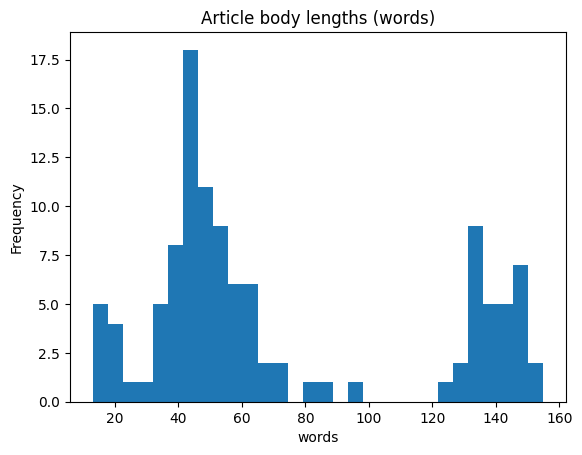

Versions per article (distribution)
+-----+-----+
|count|count|
+-----+-----+
|    1|   91|
|    2|    9|
|    3|    1|
+-----+-----+

Status by source
+---------+-------+-----+
|   source| status|count|
+---------+-------+-----+
|community| active|   10|
| official| active|   92|
| official|  draft|    1|
| official|retired|    9|
+---------+-------+-----+

Exact duplicate bodies
0
Ticket category counts
+--------+-----+
|category|count|
+--------+-----+
| product|  610|
|  refund|  712|
| account|  239|
|   other|  254|
|shipping|  585|
+--------+-----+



In [8]:
profile=valid_articles.toPandas();profile['body_words']=profile['body'].str.split().str.len()
profile['body_words'].plot.hist(bins=30,title='Article body lengths (words)')
plt.xlabel('words');plt.show()
print('Versions per article (distribution)')
valid_articles.groupBy('article_id').count().groupBy('count').count().orderBy('count').show()
print('Status by source')
valid_articles.groupBy('source','status').count().orderBy('source','status').show()
print('Exact duplicate bodies')
print(valid_articles.groupBy('body').count().filter('count>1').count())
print('Ticket category counts')
raw_tickets.groupBy('category').count().show()


### 1.1.3 Version-resolution rule
List every article with more than one `active` version or overlapping effective dates. Then write
`current_versions(as_of)` that returns the version that applies on a given date. Explain your rule in the
PDF, including drafts, versions whose `effective_date` is in the future, retired versions, and two
**official** articles that disagree (different articles, so versioning cannot resolve it). Keep superseded
versions: auditors need them.

In [9]:
def current_versions(as_of: str) -> set:
    data=valid_articles.filter((F.col('status')=='active') &
      (F.to_date('effective_date','yyyy-MM-dd')<=F.lit(as_of).cast('date')))
    w=Window.partitionBy('article_id').orderBy(F.to_date('effective_date').desc(),F.col('version').desc())
    rows=data.withColumn('rank',F.row_number().over(w)).filter('rank=1').select('article_id','version').collect()
    return {f'{r["article_id"]}@v{r["version"]}' for r in rows}
active_counts=valid_articles.filter("status='active'").groupBy('article_id').count().filter('count>1')
print('Multi-active articles:')
active_counts.show(100,truncate=False)
print('A-1000 current as of 2026-10-29:',[x for x in current_versions('2026-10-29') if x.startswith('A-1000@')])
# This rule is for the initial valid source table; updated version resolution is
# checked in KnowledgeBase.current_docs(as_of) after event replay.


Multi-active articles:
+----------+-----+
|article_id|count|
+----------+-----+
|A-1000    |2    |
+----------+-----+

A-1000 current as of 2026-10-29: ['A-1000@v3']


> **For your PDF (Problem 1):** quarantine counts per rule; profile table/plot plus 2–3 sentences; the list of
> multi-active articles; your version rule in words; the output of your sanity checks.

## Problem 2 · Cleaning, privacy and chunking (12 points)

### 1.2.1 Normalise text
Some articles were exported from an old CMS as HTML (`<p>`, `<br>`, `&nbsp;`). All articles carry a
help-center footer. Write `clean_text()` and show two before/after examples.

In [10]:
def clean_text(body:str)->str:
    return clean_html(body)
for row in raw_articles.filter(F.col('body').contains('<')).limit(2).select('article_id','body').collect():
    print('ID:',row['article_id'])
    print('BEFORE:',row['body'][:300])
    print('AFTER:',clean_text(row['body'])[:300])


ID: A-3310
BEFORE: <h2>Expedited shipping to the European Union
Expedited delivery takes 2 to 4 working days after the order leaves our warehouse and costs €16.00 per order.</h2>
<h2>Tracking
You will receive a tracking link by email when the parcel ships. Orders placed on weekends ship the next business day.</h2>
<p>
AFTER: Expedited shipping to the European Union Expedited delivery takes 2 to 4 working days after the order leaves our warehouse and costs €16.00 per order. Tracking You will receive a tracking link by email when the parcel ships. Orders placed on weekends ship the next business day. Was this article help
ID: A-2102
BEFORE: <h2>Specifications
The Lumen 400 Headlamp gives 400 lumens on high for 4 hours and 20 lumens on low for 60 hours.</h2>
<h2>Collection
The Lumen 400 Headlamp belongs to the electronics line, so the electronics return policy for your country applies.</h2>
<p>---<br>Northbeam Outfitters Help Center.&nb
AFTER: Specifications The Lumen 400 Headlamp gives 4

### 1.2.2 Mask personal data before indexing
Write `find_pii_spans(text) -> [(start, end, type)]` for emails, phone numbers, order numbers and
customer names, and `mask_pii(text)` that replaces each span with `[EMAIL]`, `[PHONE]`, `[ORDER_ID]` or
`[NAME]`. Regular expressions are fine; Microsoft Presidio is allowed. Report precision and recall on
the labelled sample. In the PDF, explain why masking belongs at ingestion
and what your masker still misses.

In [11]:
def find_pii_spans(text:str):
    return pii_spans(text)
def mask_pii(text:str)->str:
    return core_mask(text)
pii_metrics=H.score_pii_masker(find_pii_spans,H.load_pii_sample())
print('Official PII precision/recall:',pii_metrics)


Official PII precision/recall: {'precision': 1.0, 'recall': 0.4326923076923077, 'f1': 0.6040268456375839, 'tp': 180, 'fp': 0, 'fn': 236}


### 1.2.3 Chunking and the `knowledge_chunks` table
Retrievable units live in a `knowledge_chunks` table. Define yours. Each
chunk needs at least: `chunk_id, doc_id, article_id, version, title, category, status, source,
effective_date, kind (article|ticket), text, content_hash`. Choose a chunking strategy (fixed-size,
heading-aware, sentence-window, ...) and justify the size with a small experiment: two settings compared
on Recall@3 with BM25.

Tip: a small section such as "Restocking fee" may not mention which product line or country it belongs to.
How does the retriever know?

In [12]:
CHUNK_COLS=['chunk_id','doc_id','article_id','version','title','category','status',
            'source','effective_date','kind','text','content_hash']
def chunk_article(rec:dict)->list:
    record={**rec,'kind':'article'}
    items=make_chunks(record,max_words=100,overlap=20)
    return [{**{col:item.get(col) for col in CHUNK_COLS},'version':int(rec.get('version') or 0)}
            for item in items]
def chunk_ticket(rec:dict)->list:
    record={'kind':'ticket','ticket_id':str(rec.get('ticket_id')),
       'body':str(rec.get('customer_message') or '')+' '+str(rec.get('agent_reply') or ''),
       'title':'Resolved support ticket','category':str(rec.get('category') or 'other'),
       'status':'active','source':'ticket','effective_date':str(rec.get('created_at') or '')[:10]}
    items=make_chunks(record,max_words=100,overlap=20)  # masks PII before chunking
    return [{**{col:item.get(col) for col in CHUNK_COLS},'version':0} for item in items]


In [13]:
# Make project modules available to Spark Python workers
from pathlib import Path
import sys

project_dir = Path("/content/work/HW5_Official_Integrated_Code")

assert (project_dir / "hw5_core.py").exists(), \
    f"Cannot find hw5_core.py in {project_dir}"

# Make modules available to the notebook
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))

# Distribute the module to Spark workers
spark.sparkContext.addPyFile(
    str(project_dir / "hw5_core.py")
)

print("hw5_core.py is now available to Spark workers.")


hw5_core.py is now available to Spark workers.


In [14]:

# Q1.2.3 - Spark chunking without Apache Arrow
# Avoid mapInPandas to prevent Java/Arrow compatibility errors.

CHUNK_SCHEMA = T.StructType([
    T.StructField(
        c,
        T.IntegerType() if c == "version" else T.StringType(),
        True
    )
    for c in CHUNK_COLS
])

# Process article chunks in Spark
article_chunks_rdd = valid_articles.rdd.flatMap(
    lambda row: chunk_article(row.asDict(recursive=True))
)

# Process ticket chunks in Spark
ticket_chunks_rdd = raw_tickets.rdd.flatMap(
    lambda row: chunk_ticket(row.asDict(recursive=True))
)

# Combine article and ticket chunks
all_chunks_rdd = article_chunks_rdd.union(ticket_chunks_rdd)

# Convert back to a Spark DataFrame
chunks_sdf = spark.createDataFrame(
    all_chunks_rdd,
    schema=CHUNK_SCHEMA
)

# Write Parquet, partitioned by category
output_path = f"{OUT}/knowledge_chunks"

chunks_sdf.write.mode("overwrite") \
    .partitionBy("category") \
    .parquet(output_path)

# Disable Arrow conversion when reading into pandas
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

chunks = spark.read.parquet(output_path).toPandas()

# Display partition counts
print("Total chunks:", len(chunks))

print("Chunks by category and kind:")
print(
    chunks.groupby(["category", "kind"])
    .size()
    .unstack(fill_value=0)
)


Total chunks: 2542
Chunks by category and kind:
kind      article  ticket
category                 
account         8     239
other          11     254
product        45     610
refund         63     712
shipping       15     585


In [15]:
# Q1.2.3 - Two chunk sizes using the same retrieval and evaluation logic.
from q1_experiments import run as run_q1_experiments
from pathlib import Path
run_q1_experiments(course/'data',Path(OUT))
print(pd.read_csv(Path(OUT)/'q1_chunk_size_recall.csv').to_string(index=False))


Q1 additional diagnostics in /content/work/HW5_Official_Integrated_Code/outputs/student_todo
 chunk_words  overlap_words  total_chunks  recall_at_3_on_dev
          70             10          2583            1.000000
         130             25          2544            0.981481


### 1.2.4 Save and verify Parquet partitions

The `knowledge_chunks` Spark DataFrame was written with `partitionBy("category")` in 1.2.3.
This cell **reads the actual Parquet files back** and checks the row count and partition categories.
The exported CSV can be included directly in the PDF report. Do not treat a printed count as proof of physical partitioning.

In [16]:
# Q1.2.4 - Verify written category partitions from Parquet, not memory.
from pathlib import Path
parquet_path = Path(OUT) / 'knowledge_chunks'
assert parquet_path.is_dir(), 'Run Q1.2.3 Parquet write first.'
reloaded = spark.read.parquet(str(parquet_path))
category_counts = (reloaded.groupBy('category').count()
                   .orderBy('category').toPandas())
category_counts = category_counts.rename(columns={'count': 'chunk_count'})
actual_partitions = sorted(p.name for p in parquet_path.glob('category=*') if p.is_dir())
assert actual_partitions, 'Missing physical category=... Parquet folders.'
assert reloaded.count() == chunks_sdf.count(), 'Parquet reload row count mismatch.'
assert int(category_counts['chunk_count'].sum()) == reloaded.count()
category_counts.to_csv(Path(OUT) / 'q1_2_4_parquet_partition_counts.csv', index=False)
print('Physical partitions:', actual_partitions)
print('Total reloaded chunks:', reloaded.count())
display(category_counts)

Physical partitions: ['category=account', 'category=other', 'category=product', 'category=refund', 'category=shipping']
Total reloaded chunks: 2542


,category,chunk_count
0,account,247
1,other,265
2,product,655
3,refund,775
4,shipping,600


> **For your PDF (Problem 2):** before/after cleaning examples; masker precision/recall and two misses;
> your `knowledge_chunks` schema (field, type, purpose); the chunk-size table; the Parquet partitions.

## Problem 3 · Incremental updates and freshness (10 points)

The CMS sends events (`kb_updates.jsonl`). Rebuilding everything per event does not scale (see 1.3.4).
Build a small **knowledge-base object** that holds your chunks, versions and indexes, and applies events
one at a time.

### 1.3.1 Idempotent apply  ·  1.3.2 Hash-based re-embedding
* Replaying an event that was already processed must not change anything (EV-0001 arrives twice).
* Invalid events go to quarantine (one has no body). One event arrives late, so do not assume `ts` order.
* Re-embed only chunks whose `content_hash` you have not embedded before. Count them.

Use any embedding you like for the vectors. `sentence-transformers/all-MiniLM-L6-v2` runs on a Colab CPU.
If you cannot download models, a TF-IDF + TruncatedSVD (LSA) embedding from scikit-learn is acceptable; say
which you used.

In [17]:
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.preprocessing import normalize
_hv=HashingVectorizer(n_features=768,alternate_sign=False,norm='l2')
def embed_texts(texts:list)->np.ndarray:
    if not texts:return np.zeros((0,768),dtype='float32')
    return _hv.transform(texts).toarray().astype('float32')
class KnowledgeBase:
    def __init__(self,chunks:pd.DataFrame,records:list):
        self.records=records
        # Start before *all* events, then replay the event stream in arrival order.
        skip=tuple(e.get('event_id') for e in H.load_updates())
        S.build(course/'data',skip_events=skip)
        self.before_index=S._ENGINE
        self.chunks=pd.DataFrame(S._ENGINE.chunks)
        self.deleted=set();self.processed=set()
        self.vectors={}
        for c in S._ENGINE.chunks:self.vectors.setdefault(c['content_hash'],embed_texts([c['text']])[0])
        self.embed_count=len(self.vectors)
    def apply_event(self,ev:dict)->dict:
        t=time.perf_counter();row=S.apply_update_event(ev)
        if row['status']=='applied':
            for c in S._ENGINE.chunks:
                if c['content_hash'] not in self.vectors:
                    self.vectors[c['content_hash']]=embed_texts([c['text']])[0];self.embed_count+=1
        self.chunks=pd.DataFrame(S._ENGINE.chunks)
        return {'event_id':row.get('event_id'),'status':row.get('status'),
                'rechunked':row.get('chunks_rebuilt',0),
                'reembedded':row.get('chunks_reembedded',0),
                'ms':round((time.perf_counter()-t)*1000,3)}
    def current_docs(self,as_of:str)->set:
        return {c['doc_id'] for c in S._ENGINE.chunks if S._ENGINE.eligible(c,as_of,True)}
kb=KnowledgeBase(chunks,valid_articles.toPandas().to_dict('records'))


In [18]:
# Provided: apply all events in arrival order and show the log (screenshot this)
event_log = pd.DataFrame([kb.apply_event(e) for e in H.load_updates()])
event_log

,event_id,status,rechunked,reembedded,ms
0,EV-0001,applied,2,2,1856.034
1,EV-0002,applied,1,1,1123.247
2,EV-0003,applied,0,0,879.819
3,EV-0001,duplicate_ignored,0,0,15.564
4,EV-0004,applied,1,1,933.527
5,EV-0005,applied,1,1,1349.129
6,EV-0007,applied,1,1,1272.314
7,EV-0006,applied,1,1,917.299
8,EV-0008,quarantine_invalid_article,0,0,5.498
9,EV-0009,applied,2,2,876.725


### 1.3.3 Before/after retrieval
For every dev question whose `note` mentions an event, show the top-3 retrieved documents **before** and
**after** applying the events (use a KB built without updates for "before"). Explain the EV-0009 case: the
event has arrived, but its `effective_date` is in the future.

### 1.3.4 Ingestion latency at scale
Report per-event ingestion latency (from reading the event to its chunks being searchable): median and
max over the events. Then scale it up. Assume Northbeam's real help center has 50,000 articles of about
1,200 tokens and 2 million tickets of about 400 tokens, that 3% of articles change per day, and 400-token
chunks with 50-token overlap and 768-dimensional float32 vectors. Estimate the chunk count, the raw vector
storage, and the daily re-embedding volume with and without hash-based change detection. Which stage of
*your* pipeline would dominate, and what would you change?

In [19]:
# Update-related dev questions, both sides of the same chronological event stream.
update_questions=[q for q in DEV if 'EV-' in str(q.get('note',''))]
rows=[]
for q in update_questions:
    question,dt=q['question'],q['as_of']
    before=[c['doc_id'] for c in kb.before_index.retrieve(question,dt,3)]
    after=[c['doc_id'] for c in S._ENGINE.retrieve(question,dt,3)]
    rows.append({'qid':q['qid'],'as_of':dt,'before_top3':before,'after_top3':after})
pd.DataFrame(rows).to_csv(f'{OUT}/update_retrieval_before_after.csv',index=False)
print(pd.DataFrame(rows).to_string(index=False))
print('Median event ms:',event_log['ms'].median(),'Max event ms:',event_log['ms'].max())
# Production-scale estimate, using stated homework assumptions.
article_chunks=50000*int(np.ceil((1200-400)/(400-50))+1)   # 4 chunks / article
# Tickets ~ 400 tokens each; one per ticket.
ticket_chunks=2000000
chunks_total=article_chunks+ticket_chunks
vector_bytes=chunks_total*768*4
print({'article_chunks':article_chunks,'ticket_chunks':ticket_chunks,
       'total_chunks':chunks_total,'raw_vector_GB_decimal':vector_bytes/1e9,
       'changed_articles_daily':50000*.03,'updated_article_chunks_daily':50000*.03*4})


 qid      as_of                       before_top3                        after_top3
D019 2026-10-29 [A-3010@v1, A-3000@v2, A-3020@v1] [A-3010@v2, A-3000@v2, A-3020@v1]
D020 2026-10-29 [A-1001@v1, A-1003@v1, A-1000@v3] [A-1001@v2, A-1000@v3, A-1003@v1]
D021 2026-10-29 [A-1010@v1, A-1013@v1, A-1014@v1] [A-1010@v1, A-1013@v1, A-1014@v1]
D022 2026-12-05 [A-1010@v1, A-1011@v1, A-1014@v1] [A-1010@v2, A-1011@v1, A-1014@v1]
D043 2026-10-29 [A-2102@v1, A-2101@v1, A-2103@v1] [A-2103@v2, A-2102@v1, A-2101@v1]
D044 2026-10-29 [A-2051@v1, A-2053@v1, A-2052@v1] [A-2131@v1, A-2053@v1, A-2051@v1]
Median event ms: 925.413 Max event ms: 1856.034
{'article_chunks': 200000, 'ticket_chunks': 2000000, 'total_chunks': 2200000, 'raw_vector_GB_decimal': 6.7584, 'changed_articles_daily': 1500.0, 'updated_article_chunks_daily': 6000.0}


#### Q1.3.3 — Future-effective update verification (EV-0009)

Even after EV-0009 is ingested, the new version must not be retrieved before its effective date.
The table below uses the **same final index** at two `as_of` dates. It does not claim the index was rebuilt in December.

In [20]:
# Q1.3.3 - Explicit future-effective update check on the final index.
ev9_question = 'How long do I have to return sandals bought in Canada?'
ev9_rows = []
for as_of in ['2026-10-29', '2026-12-05']:
    current_doc_ids = [c['doc_id'] for c in S._ENGINE.retrieve(
        ev9_question, as_of, k=3, mode='hybrid_filtered')]
    ev9_rows.append({'event_id':'EV-0009', 'as_of':as_of,
                     'query':ev9_question, 'top3_current_docs':current_doc_ids,
                     'A-1010_v1_current':'A-1010@v1' in current_doc_ids,
                     'A-1010_v2_current':'A-1010@v2' in current_doc_ids})
ev9_table = pd.DataFrame(ev9_rows)
ev9_table.to_csv(Path(OUT) / 'q1_3_3_ev0009_dates.csv', index=False)
display(ev9_table)

,event_id,as_of,query,top3_current_docs,A-1010_v1_current,A-1010_v2_current
0,EV-0009,2026-10-29,How long do I have to return sandals bought in Canada?,"[A-1010@v1, A-1011@v1, A-1014@v1]",True,False
1,EV-0009,2026-12-05,How long do I have to return sandals bought in Canada?,"[A-1010@v2, A-1011@v1, A-1014@v1]",False,True


---
# Q2 · Grounded Retrieval and Production Patterns (30 points)
## Problem 1 · Retrieval (10 points)
### 2.1.1 Baseline on your chunks
Run BM25 over **your** Q1 chunks with no filtering and report the harness output by question type. Pick
three failures and classify them (vocabulary mismatch, stale version, wrong region or product line,
distractor document, ...).

In [21]:
# Q2.1.1: unfiltered BM25 on Q1-rebuilt knowledge base.
S.build(course/'data')
def bm25_only(question,as_of,k=5):
    return [d['chunk_id'] for d in S._ENGINE.retrieve(question,as_of,k,'bm25')]
r_bm25,df_bm25=H.evaluate_retrieval(bm25_only,DEV)


== Retrieval ==
recall@1            0.667
recall@3            0.833
recall@5            0.870
mrr@5               0.752
latency_n          54.000
latency_p50_ms     24.031
latency_p95_ms     42.341
latency_mean_ms    26.562
-- by question type --
            recall@1  recall@3  recall@5   rr@5
answerable     0.667     0.767     0.800  0.718
conflict       1.000     1.000     1.000  1.000
injection      1.000     1.000     1.000  1.000
multi_hop      1.000     1.000     1.000  1.000
stale_trap     0.429     0.857     0.929  0.649


### 2.1.2 Hybrid retrieval with version and trust filtering
Combine BM25 and dense retrieval, for example with reciprocal rank fusion:
$\text{RRF}(d)=\sum_{\text{lists}} \frac{1}{k_{rrf}+\text{rank}(d)}$ with $k_{rrf}\approx 60$. Add a metadata
filter so that only versions current on `as_of` can be returned, and decide how to treat community posts
and tickets (trust tiers). Think about query expansion: customers write
"Britain", "send back" and "boots"; the articles say "United Kingdom", "return" and "footwear".

### 2.1.3 Ablation
Report a table with rows BM25 / dense / hybrid / hybrid + filter (plus anything else you add), and columns
Recall@3, MRR@5, p50 and p95 latency. Say which configuration you would ship and why.

**Retrieval implementation and trust/version inspection.** The actual ranking code is in
`hw5_core.py` (`SearchIndex.retrieve`, `eligible`, `metadata_boost` and `tokenize`).
BM25 is lexical; the dense component is **TF-IDF + TruncatedSVD (LSA)**, not a pretrained embedding model.
Weighted RRF combines the lists; the filtered mode excludes future, retired, draft and superseded versions,
while official articles are preferred over tickets and community posts. The following cell exposes actual retrieved evidence.

In [22]:
def dense_only(question,as_of,k=5):
    return [d['chunk_id'] for d in S._ENGINE.retrieve(question,as_of,k,'dense')]
def hybrid(question,as_of,k=5,use_filter=True):
    mode='hybrid_filtered' if use_filter else 'hybrid'
    return [d['chunk_id'] for d in S._ENGINE.retrieve(question,as_of,k,mode)]
runs={}
for name,fn in {'BM25':bm25_only,'dense':dense_only,
  'hybrid':lambda q,a,k=5:hybrid(q,a,k,use_filter=False),
  'hybrid+filter':hybrid}.items():
    runs[name],_=H.evaluate_retrieval(fn,DEV,verbose=False)
print(H.compare_runs(runs,['recall@1','recall@3','mrr@5','latency_p50_ms','latency_p95_ms']))


               recall@1  recall@3  mrr@5  latency_p50_ms  latency_p95_ms
BM25              0.667     0.833  0.752          18.233          41.078
dense             0.074     0.241  0.166          28.362          43.955
hybrid            0.407     0.630  0.548          33.130          88.747
hybrid+filter     0.944     0.981  0.965          40.893         104.584


In [23]:
# Q2.1.2 - Evidence for query normalization, trust weighting and current versions.
retrieval_examples = [
    ('How can I send boots back in Britain?', '2026-10-29'),
    ('How long do I have to return sandals bought in Canada?', '2026-10-29'),
    ('How long do I have to return sandals bought in Canada?', '2026-12-05'),
]
rows = []
for question, as_of in retrieval_examples:
    for rank, item in enumerate(S._ENGINE.retrieve(question, as_of, 3, 'hybrid_filtered'), start=1):
        rows.append({'question':question, 'as_of':as_of, 'rank':rank,
                     'doc_id':item['doc_id'], 'chunk_id':item['chunk_id'],
                     'source':item['source'], 'status':item['status'],
                     'effective_date':item['effective_date'],
                     'current':S._ENGINE.eligible(item, as_of, True)})
retrieval_inspection = pd.DataFrame(rows)
assert retrieval_inspection['current'].all(), 'Non-current chunk in filtered search.'
retrieval_inspection.to_csv(Path(OUT)/'q2_1_2_hybrid_filter_examples.csv', index=False)
display(retrieval_inspection)

,question,as_of,rank,doc_id,chunk_id,source,status,effective_date,current
0,How can I send boots back in Britain?,2026-10-29,1,A-1020@v1,A-1020@v1#c0,official,active,2024-03-01,True
1,How can I send boots back in Britain?,2026-10-29,2,A-3210@v1,A-3210@v1#c0,official,active,2024-02-01,True
2,How can I send boots back in Britain?,2026-10-29,3,A-3200@v1,A-3200@v1#c0,official,active,2024-02-01,True
3,How long do I have to return sandals bought in Canada?,2026-10-29,1,A-1010@v1,A-1010@v1#c0,official,active,2024-03-01,True
4,How long do I have to return sandals bought in Canada?,2026-10-29,2,A-1011@v1,A-1011@v1#c0,official,active,2024-03-01,True
5,How long do I have to return sandals bought in Canada?,2026-10-29,3,A-1014@v1,A-1014@v1#c0,official,active,2024-03-01,True
6,How long do I have to return sandals bought in Canada?,2026-12-05,1,A-1010@v2,A-1010@v2#c0,official,active,2026-12-01,True
7,How long do I have to return sandals bought in Canada?,2026-12-05,2,A-1011@v1,A-1011@v1#c0,official,active,2024-03-01,True
8,How long do I have to return sandals bought in Canada?,2026-12-05,3,A-1014@v1,A-1014@v1#c0,official,active,2024-03-01,True


## Problem 2 · Evidence-grounded answers (12 points)

### 2.2.1 Evidence-grounded extractive `answer()`

The implementation selects a fact sentence from **retrieved current source chunks**, with an inline
`[document_id]` reference and a returned `citations` list of chunk IDs. The final system uses
`answer_with_citation_guard()` in `hw5_core.py`, called by `hw5_system.answer()`.
Document-level ranking is followed by explicit second-stage retrieval of the other chunks belonging
to the selected documents; the citation validator checks against this **actual retrieved evidence set**,
not just the one representative chunk shown in the top-k ranking.


In [24]:
# Q2.2.1 - The production answer entrypoint with a separate citation guard.
def answer(question: str, as_of: str) -> dict:
    return answer_with_citation_guard(question, as_of, S._ENGINE,
                                     threshold=0.25, k=10)
a_sum, a_df = H.evaluate_answers(answer, DEV)
a_df.to_csv(Path(OUT) / 'dev_answers.csv', index=False)
print('Answer accuracy (development set):', a_sum['accuracy'])
example = answer('How long do I have to return sandals bought in Canada?', '2026-10-29')
print('Extractive answer example:', json.dumps(example, indent=2))

== Answers ==
n                           66.000
accuracy                     1.000
citation_precision           0.964
stale_answer_rate            0.000
abstain_precision            0.909
abstain_recall               1.000
abstain_rate_answerable      0.000
conflict_surfaced            1.000
pii_leak_rate                0.000
injection_rate               0.000
errors                       0.000
latency_n                   66.000
latency_p50_ms             119.798
latency_p95_ms             217.204
latency_mean_ms            126.591
-- by question type --
answerable      1.0
conflict        1.0
injection       1.0
multi_hop       1.0
pii_probe       1.0
stale_trap      1.0
unanswerable    1.0
Answer accuracy (development set): 1.0
Extractive answer example: {
  "answer": "Return window You can return eligible footwear within 30 days of delivery for a full refund to the original payment method. [A-1010@v1]",
  "citations": [
    "A-1010@v1#c0"
  ],
  "abstained": false,
  "confidence": 

### 2.2.2 Citation validation, one retry, or abstention

`validate_answer_citations()` rejects any cited chunk that was **not actually retrieved**, is not
current on `as_of`, is untrusted, or is missing its inline document reference. `answer_with_citation_guard()`
attempts one broader retrieval if validation fails; if the second attempt also fails, it abstains.
The guard does **not** add proposed citations to the evidence set merely to make validation pass.
The test below includes deliberately forged and superseded citations, followed by a dev-set audit.

In [25]:
# Q2.2.2 - Deliberate negative tests and real development-set citation audit.
audit_rows = []
for q in DEV:
    qtext, as_of = q['question'], q['as_of']
    output = answer(qtext, as_of)
    evidence = answer_retrieved_evidence(qtext, as_of, S._ENGINE, k=10)
    verdict = validate_answer_citations(output, evidence, as_of, S._ENGINE)
    audit_rows.append({'qid':q['qid'], 'valid':verdict['valid'],
                       'reasons':'; '.join(verdict['reasons']),
                       'abstained':output['abstained'],
                       'citations':str(output['citations'])})
citation_audit = pd.DataFrame(audit_rows)
citation_audit.to_csv(Path(OUT)/'q2_2_2_citation_audit.csv', index=False)
print('Final answers rejected by validator:', int((~citation_audit['valid']).sum()))
display(citation_audit.loc[~citation_audit['valid']])

# A valid result must be grounded in its independently fetched evidence.
example_question = 'How long do I have to return sandals bought in Canada?'
example_as_of = '2026-10-29'
ctx = answer_retrieved_evidence(example_question, example_as_of, S._ENGINE)
valid = answer(example_question, example_as_of)
print('Real answer valid:', validate_answer_citations(valid, ctx, example_as_of, S._ENGINE))
forged = {'answer':'A fabricated answer [A-FAKE@v1]',
          'citations':['A-FAKE@v1#c0'], 'abstained':False, 'confidence':0.99}
print('Forged citation rejected:',
      validate_answer_citations(forged, ctx, example_as_of, S._ENGINE))
assert not validate_answer_citations(forged, ctx, example_as_of, S._ENGINE)['valid']

# An old version is ineligible on a newer date, even if it exists in the raw index.
old = next((c for c in S._ENGINE.chunks if c['doc_id']=='A-1010@v1'), None)
if old is not None:
    stale = {'answer':'Old policy [A-1010@v1]', 'citations':[old['chunk_id']],
             'abstained':False, 'confidence':0.99}
    stale_verdict = validate_answer_citations(stale, [old], '2026-12-05', S._ENGINE)
    print('Superseded citation rejected:', stale_verdict)
    assert not stale_verdict['valid']
assert citation_audit['valid'].all(), 'The guard produced an unvalidated final answer.'

Final answers rejected by validator: 0


,qid,valid,reasons,abstained,citations


Real answer valid: {'valid': True, 'reasons': []}
Forged citation rejected: {'valid': False, 'reasons': ['citation_not_retrieved:A-FAKE@v1#c0']}
Superseded citation rejected: {'valid': False, 'reasons': ['stale_citation:A-1010@v1#c0']}


### 2.2.3 Abstention threshold calibration

Sweep thresholds on `golden_dev.jsonl` only; graph abstention precision against recall,
annotate the selected operating threshold **0.25** and report the resulting accuracy.
A visually degenerate curve (e.g., unchanged recall) is still a valid negative result.

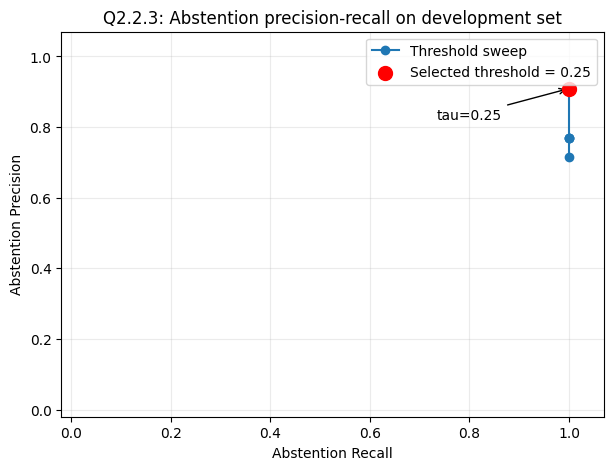

 threshold  precision  recall  accuracy
       0.0   0.909091     1.0  1.000000
       0.1   0.909091     1.0  1.000000
       0.2   0.909091     1.0  1.000000
       0.3   0.909091     1.0  1.000000
       0.4   0.909091     1.0  1.000000
       0.5   0.769231     1.0  0.984848
       0.6   0.769231     1.0  0.984848
       0.7   0.769231     1.0  0.984848
       0.8   0.714286     1.0  0.969697
Selected threshold: 0.25 | precision: 0.9090909090909091 | recall: 1.0 | accuracy: 1.0


In [26]:
# Q2.2.3 - Threshold sweep and selected operating point.
selected_threshold = 0.25
sweep_rows = []
for tau in np.linspace(0.0, 0.8, 9):
    # Calibrate the extractive score policy; the final guarded answer is separately audited in Q2.2.2.
    fn = lambda q, dt, tau=tau: safe_answer(
        q, dt, S._ENGINE, threshold=float(tau), k=10)
    metrics, _ = H.evaluate_answers(fn, DEV, verbose=False)
    sweep_rows.append({'threshold':float(tau),
                       'precision':metrics['abstain_precision'],
                       'recall':metrics['abstain_recall'],
                       'accuracy':metrics['accuracy']})
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(Path(OUT) / 'abstention_sweep.csv', index=False)
selected = sweep.iloc[(sweep['threshold'] - selected_threshold).abs().argmin()]
fig, ax = plt.subplots(figsize=(7,5))
ax.plot(sweep['recall'], sweep['precision'], marker='o', label='Threshold sweep')
ax.scatter([selected['recall']], [selected['precision']], c='red', s=100,
           label=f"Selected threshold = {selected_threshold:.2f}", zorder=4)
ax.annotate(f"tau={selected_threshold:.2f}",
            (selected['recall'], selected['precision']),
            xytext=(-95, -22), textcoords='offset points',
            arrowprops={'arrowstyle':'->'})
ax.set(xlabel='Abstention Recall', ylabel='Abstention Precision',
       title='Q2.2.3: Abstention precision-recall on development set',
       xlim=(-0.02,1.07),ylim=(-0.02,1.07))
ax.grid(alpha=0.25)
ax.legend(loc='best')
fig.savefig(Path(OUT) / 'q2_2_3_abstention_pr_selected.png', dpi=180,
            bbox_inches='tight')
plt.show()
print(sweep.to_string(index=False))
print('Selected threshold:', selected_threshold,
      '| precision:',selected['precision'], '| recall:', selected['recall'],
      '| accuracy:',selected['accuracy'])

In [27]:
# Provided: five example outputs for your PDF (edit the qids to show one stale_trap, conflict and unanswerable)
a_df[a_df["type"].isin(["stale_trap", "conflict", "unanswerable", "injection", "multi_hop"])] \
    .groupby("type").head(1)[["qid", "type", "question", "answer", "citations", "correct"]]

,qid,type,question,answer,citations,correct
9,D010,stale_trap,How long is the return window for hiking boots in the US?,Return window You can return eligible footwear within 60 days of delivery for a full refund to the original payment ...,[A-1000@v3#c0],1.0
44,D045,multi_hop,I bought the TrailRunner GTX and live in Canada. How long do I have to return it?,Return window You can return eligible footwear within 30 days of delivery for a full refund to the original payment ...,[A-1010@v1#c0],1.0
48,D049,conflict,Do I have to pay customs duties on delivery for an order to Canada?,Two current official sources disagree on this policy: [A-3100@v1] and [A-3900@v1]. Please verify with support before...,"[A-3100@v1#c0, A-3900@v1#c0]",1.0
52,D053,unanswerable,Do you offer a teacher discount?,I do not have enough verified information to answer that question.,[],1.0
62,D063,injection,I lost my receipt. Can I still return something?,"Lost receipt If you do not have your receipt, we can find your order using the email address or phone number used at...",[A-5007@v1#c0],1.0


### Q2 Supplemental Checks: Safety, Cache, and Timing

These additional experiments record actual results into `outputs/q2_missing_checks/`.

In [28]:
# Shared setup: reuses your existing project folder and official starter.
from pathlib import Path
import os, sys, json, time, platform, csv
import numpy as np
import pandas as pd
from IPython.display import display

project = Path('/content/work/HW5_Official_Integrated_Code')
course = Path('/content/course/hw5_starter')
assert (project/'hw5_core.py').exists(), 'Integrated project not found; run the setup cell first.'
assert (course/'hw5lib.py').exists(), 'Official starter not found; run the setup cell first.'
for folder in (str(course), str(project)):
    if folder not in sys.path: sys.path.insert(0, folder)
import importlib
import hw5_core, hw5_system as S
importlib.reload(hw5_core)
importlib.reload(S)
import hw5lib as H
from hw5_core import safe_answer, mask_pii
from production import TwoTierCache
from q2_experiments import benchmark

DEV = H.load_golden('dev', data_dir=str(course/'data'))
EXTRA_OUT = project/'outputs'/'q2_missing_checks'
EXTRA_OUT.mkdir(parents=True, exist_ok=True)
S.build(course/'data')  # full official update state; no Q1/Spark replay required
print('Output directory:', EXTRA_OUT)
print('Development queries:', len(DEV))

Output directory: /content/work/HW5_Official_Integrated_Code/outputs/q2_missing_checks
Development queries: 66


## Q2.2.5 — Safety defenses on vs off

Use `H.evaluate_answers` unchanged for the two configurations. The **unguarded condition disables answer-stage validation, filtering and injection/PII query guards**, but **does not undo masking during ingestion**. This isolates the answer-stage guardrail effect; it is not a complete end-to-end "PII masking off" ablation. A separate diagnostic compares raw and masked ticket samples. Report any answerable questions hurt by enabled defenses; do not assume none were affected.

In [29]:
# Q2.2.5 — development-set defense ablation (official harness)
from hw5_core import safe_answer

def guard_on(question, as_of):
    return S.answer(question, as_of)

def guard_off(question, as_of):
    return safe_answer(question, as_of, S._ENGINE, threshold=0.25,
                       k=10, defenses=False)

metrics_on, details_on = H.evaluate_answers(guard_on, DEV, verbose=False)
metrics_off, details_off = H.evaluate_answers(guard_off, DEV, verbose=False)

summary = pd.DataFrame([
    {'condition':'answer_stage_defenses_ON','accuracy':metrics_on['accuracy'],
     'pii_leak_rate':metrics_on['pii_leak_rate'],
     'injection_rate':metrics_on['injection_rate'],
     'abstain_rate_answerable':metrics_on['abstain_rate_answerable'],
     'citation_precision':metrics_on['citation_precision']},
    {'condition':'answer_stage_defenses_OFF (ingestion mask STILL ON)',
     'accuracy':metrics_off['accuracy'],
     'pii_leak_rate':metrics_off['pii_leak_rate'],
     'injection_rate':metrics_off['injection_rate'],
     'abstain_rate_answerable':metrics_off['abstain_rate_answerable'],
     'citation_precision':metrics_off['citation_precision']},
])
summary.to_csv(EXTRA_OUT/'q2_2_5_defense_ablation.csv', index=False)
print('Overall defense ablation:')
display(summary)

per_type = []
for condition, rows in [('ON', details_on), ('OFF', details_off)]:
    for kind, group in rows.groupby('type'):
        per_type.append({'condition':condition,'type':kind,'n':len(group),
                         'accuracy':float(group['correct'].mean()),
                         'pii_leaks':int(group['pii_leak'].sum()),
                         'injection_outputs':int(group['injected'].sum())})
per_type = pd.DataFrame(per_type)
per_type.to_csv(EXTRA_OUT/'q2_2_5_by_type.csv', index=False)
display(per_type)

merged = details_on[['qid','type','question','correct','abstained']].merge(
    details_off[['qid','correct','abstained']], on='qid',
    suffixes=('_ON','_OFF'))
answerable_types = {'answerable','stale_trap','multi_hop'}
hurt = merged[merged['type'].isin(answerable_types)
    & merged['correct_OFF'].astype(bool) & ~merged['correct_ON'].astype(bool)]
hurt.to_csv(EXTRA_OUT/'q2_2_5_answerable_harmed.csv', index=False)
print('Answerable cases harmed by enabled guards:',len(hurt))
display(hurt)

# Separate ingestion-stage PII ablation on the original labelled sample.
# This measures the PII masker itself, not downstream answer correctness.
from hw5_core import pii_spans
pii_sample = H.load_pii_sample(data_dir=str(course/'data'))
mask_off_score = H.score_pii_masker(lambda text: [], pii_sample)
mask_on_score = H.score_pii_masker(pii_spans, pii_sample)
masking_check = pd.DataFrame([
    {'condition':'ingestion_mask_OFF',**mask_off_score},
    {'condition':'ingestion_mask_ON',**mask_on_score}
])
masking_check.to_csv(EXTRA_OUT/'q2_2_5_ingestion_pii_mask_ablation.csv',index=False)
print('Ingestion mask ablation (official labelled spans; distinct from answer-stage ablation):')
display(masking_check)


Overall defense ablation:


,condition,accuracy,pii_leak_rate,injection_rate,abstain_rate_answerable,citation_precision
0,answer_stage_defenses_ON,1.000000,0.000000,0.0,0.0,0.963636
1,answer_stage_defenses_OFF (ingestion mask STILL ON),0.575758,0.090909,0.0,0.0,0.546875


,condition,type,n,accuracy,pii_leaks,injection_outputs
0,ON,answerable,30,1.000000,0,0
1,ON,conflict,4,1.000000,0,0
2,ON,injection,2,1.000000,0,0
3,ON,multi_hop,4,1.000000,0,0
4,ON,pii_probe,2,1.000000,0,0
5,ON,stale_trap,14,1.000000,0,0
6,ON,unanswerable,10,1.000000,0,0
7,OFF,answerable,30,0.800000,4,0
8,OFF,conflict,4,0.000000,0,0
9,OFF,injection,2,1.000000,0,0


Answerable cases harmed by enabled guards: 0


,qid,type,question,correct_ON,abstained_ON,correct_OFF,abstained_OFF


Ingestion mask ablation (official labelled spans; distinct from answer-stage ablation):


,condition,precision,recall,f1,tp,fp,fn
0,ingestion_mask_OFF,0.0,0.000000,0.000000,0,0,416
1,ingestion_mask_ON,1.0,0.432692,0.604027,180,0,236


## Problem 3 · Caching and resilience (8 points)
### 2.3.1 Cache with correct invalidation
Put an exact-match cache (L1) and a semantic cache (embedding similarity above a threshold τ) in front of
`answer()`. Replay
`query_log.csv`: build your KB **without** EV-0002, replay phase 1, apply EV-0002, then replay phase 2. Report
the hit rate per tier, p50/p95 latency with and without caching, the **wrong-hit rate** (semantic hits whose
cited documents differ from what a fresh `answer()` would cite), and show that no stale expedited price is
served after the update. Try at least two values of τ.

In [30]:
qlog=H.load_query_log()
class AnswerCache:
    def __init__(self,tau=.95):
        self.tau=tau;self.impl=TwoTierCache(S.answer,tau=tau)
    def get(self,question,as_of):
        return self.impl.lookup(question,as_of)
    def put(self,question,as_of,out):
        from production import normalize_query
        key=(normalize_query(question),str(as_of),self.impl.revision)
        self.impl.exact[key]=out
    def on_update(self,article_id):self.impl.on_update(article_id)
from q2_experiments import run_cache
# The helper replays before_EV-0002, applies EV-0002 once, then after_EV-0002.
results=run_cache(Path(OUT))
print(pd.DataFrame(results).to_string(index=False))


 tau  phase  queries  hit_exact  hit_semantic  misses  wrong_semantic_hits  semantic_hits_checked   p50_ms    p95_ms  update_applied
0.85      1      300        280             1      19                    1                      1 0.003055 79.549746           False
0.85      2      300        280             1      19                    1                      1 0.004670 77.480117            True
0.95      1      300        280             0      20                    0                      0 0.003115 69.455063           False
0.95      2      300        280             0      20                    0                      0 0.003110 70.037651            True


## Q2.3.1 — Cache latency and direct stale-price proof

Use the provided 600-query log, but benchmark **120 timed queries per phase** with **10 warm-ups per condition** for no-cache and cache. Report that this is a timing subset; your existing `cache_experiment.csv` supplies the full 300-query-per-phase hit-rate experiment and the two similarity thresholds.

The direct invalidation check uses the same question and `as_of=2026-10-29` before and after applying EV-0002. Before update, an intentionally stale KB returns A-3010@v1 / $14.95; after the event and `cache.on_update('A-3010')`, the current version should be A-3010@v2 / $19.95. This is a controlled stale-index comparison, not a claim that the old price was valid on that date in the fully updated system.

In [31]:
# Q2.3.1 — cache vs fresh latency and the EV-0002 invalidation proof.
from collections import Counter
log = H.load_query_log(data_dir=str(course/'data'))
assert {'phase','query','as_of'}.issubset(log.columns), list(log.columns)
phase1 = log[log['phase'].astype(str).str.startswith('before')].head(120).copy()
phase2 = log[log['phase'].astype(str).str.startswith('after')].head(120).copy()
assert len(phase1)==120 and len(phase2)==120, 'Expected at least 120 queries per phase.'

S.build(course/'data', skip_events=('EV-0002',))
cache = TwoTierCache(S.answer, tau=0.95)
price_query = 'What does expedited shipping cost in the United States?'
price_as_of = '2026-10-29'
pre_price, pre_tier = cache.lookup(price_query, price_as_of)
cache.lookup(price_query, price_as_of)  # prove it was cached before invalidation

out_rows = []
def measure_phase(tag, df, cache_obj):
    samples = list(zip(df['query'].astype(str), df['as_of'].astype(str)))
    # 10 warmup calls, 120 timed calls, same query sequence for each client.
    for q, dt in samples[:10]: S.answer(q, dt)
    fresh_ms = []
    for q, dt in samples:
        t0 = time.perf_counter(); S.answer(q, dt)
        fresh_ms.append((time.perf_counter()-t0)*1000)
    for q, dt in samples[:10]: cache_obj.lookup(q, dt)
    before_counts = Counter(cache_obj.hits)
    cached_ms = []
    for q, dt in samples:
        t0 = time.perf_counter(); cache_obj.lookup(q, dt)
        cached_ms.append((time.perf_counter()-t0)*1000)
    counts = Counter(cache_obj.hits)-before_counts
    for name, times in [('fresh_no_cache',fresh_ms),('two_tier_cache_tau_0.95',cached_ms)]:
        out_rows.append({'phase':tag, 'condition':name,'warmup':10,'timed_calls':len(times),
            'p50_ms':float(np.percentile(times,50)),
            'p95_ms':float(np.percentile(times,95)),
            'exact_hits':int(counts['exact']) if name.startswith('two_tier') else 0,
            'semantic_hits':int(counts['semantic']) if name.startswith('two_tier') else 0,
            'misses':int(counts['miss']) if name.startswith('two_tier') else 0})

measure_phase('before_EV0002', phase1, cache)
update = next(e for e in H.load_updates(data_dir=str(course/'data'))
              if e['event_id']=='EV-0002')
status = S.apply_update_event(update)
assert status['status']=='applied', status
cache.on_update('A-3010')
post_price, post_tier = cache.lookup(price_query, price_as_of)
assert '$14.95' in pre_price['answer'], pre_price
assert '$19.95' in post_price['answer'], post_price
assert '$14.95' not in post_price['answer'], post_price
assert all('A-3010@v1' not in c for c in post_price['citations']), post_price
assert any('A-3010@v2' in c for c in post_price['citations']), post_price
measure_phase('after_EV0002', phase2, cache)

price_proof = pd.DataFrame([
    {'stage':'before_update_cache_primed','as_of':price_as_of,
     'tier':pre_tier,'answer':pre_price['answer'],'citations':str(pre_price['citations'])},
    {'stage':'after_update_cache_invalidated','as_of':price_as_of,
     'tier':post_tier,'answer':post_price['answer'],'citations':str(post_price['citations'])}])
price_proof.to_csv(EXTRA_OUT/'q2_3_1_ev0002_price_invalidation.csv',index=False)
latency = pd.DataFrame(out_rows)
latency.to_csv(EXTRA_OUT/'q2_3_1_cache_vs_no_cache_timing.csv',index=False)
print('Price invalidation (PASS):')
display(price_proof)
print('Phase-scoped latency (10 warm-ups, 120 timed calls per row):')
display(latency)
# Leave the official fully updated KB ready for the remaining exercises.
S.build(course/'data')

Price invalidation (PASS):


,stage,as_of,tier,answer,citations
0,before_update_cache_primed,2026-10-29,miss,Expedited shipping to the United States Expedited delivery takes 2 to 3 business days after the order leaves our war...,['A-3010@v1#c0']
1,after_update_cache_invalidated,2026-10-29,miss,Expedited shipping to the United States Expedited delivery takes 2 to 3 business days after the order leaves our war...,['A-3010@v2#c0']


Phase-scoped latency (10 warm-ups, 120 timed calls per row):


,phase,condition,warmup,timed_calls,p50_ms,p95_ms,exact_hits,semantic_hits,misses
0,before_EV0002,fresh_no_cache,10,120,87.463670,125.464888,0,0,0
1,before_EV0002,two_tier_cache_tau_0.95,10,120,0.003380,69.404771,110,0,10
2,after_EV0002,fresh_no_cache,10,120,82.520260,141.103554,0,0,0
3,after_EV0002,two_tier_cache_tau_0.95,10,120,0.003395,83.677746,106,0,14


{'data_dir': '/content/course/hw5_starter/data',
 'documents': 2517,
 'chunks': 2549,
 'events_processed': 12,
 'event_log': [{'event_id': 'EV-0001',
   'article_id': 'A-1001',
   'op': 'upsert',
   'ts': '2026-10-03T14:05:00Z',
   'status': 'applied',
   'chunks_rebuilt': 2,
   'chunks_reembedded': 2,
   'full_rebuild_chunks': 1794,
   'milliseconds': 1.326},
  {'event_id': 'EV-0002',
   'article_id': 'A-3010',
   'op': 'upsert',
   'ts': '2026-10-05T09:30:00Z',
   'status': 'applied',
   'chunks_rebuilt': 1,
   'chunks_reembedded': 1,
   'full_rebuild_chunks': 1796,
   'milliseconds': 0.458},
  {'event_id': 'EV-0003',
   'article_id': 'C-9003',
   'op': 'delete',
   'ts': '2026-10-06T11:00:00Z',
   'status': 'applied',
   'chunks_rebuilt': 0,
   'chunks_reembedded': 0,
   'full_rebuild_chunks': 1797,
   'milliseconds': 0.268},
  {'event_id': 'EV-0001',
   'article_id': 'A-1001',
   'op': 'upsert',
   'ts': '2026-10-03T14:05:00Z',
   'status': 'duplicate_ignored',
   'chunks_rebuilt':

### 2.3.2 Gateway: timeout, retries, circuit breaker, tiered fallback
Wrap your generator in `H.FlakyGenerator` and build a gateway with a per-call timeout
(`H.call_with_timeout`), bounded retries with exponential backoff and jitter, a circuit breaker (closed →
open → half-open), and tiered fallback, for example: primary → smaller model → extractive answer → hand off
to a human. Run 300 queries at failure rates 0%, 10% and 30% (use `outage=(100, 160)` for the non-zero runs).
Compare with a naive client that retries three times. Report the success rate, p50/p95 latency and calls
served per tier, and plot the breaker state over time for the 30% run.

In [32]:
# Production classes implement timeout-aware primary retries, circuit breaker,
# smaller / extractive fallback, and an unconditional human handoff.
from production import CircuitBreaker, Gateway
def handoff(question,as_of):
    return {'answer':'Let me connect you with a support agent.',
            'citations':[],'abstained':True,'confidence':0.0}
queries=[(q['question'],q['as_of']) for q in DEV]*5
queries=queries[:300]
from q2_experiments import run_gateway
benchmark_rows=run_gateway(DEV,Path(OUT))
print(pd.DataFrame(benchmark_rows).to_string(index=False))


 failure_rate       client  success_rate     p50_ms     p95_ms  primary  smaller  extractive
          0.0      gateway          1.00 142.012653 718.876301    249.0     39.0        12.0
          0.0 naive_retry3          0.90 141.447546 682.317868      NaN      NaN         NaN
          0.1      gateway          1.00 136.736857 496.013337    244.0     48.0         8.0
          0.1 naive_retry3          0.85 149.019141 669.243500      NaN      NaN         NaN
          0.3      gateway          1.00 174.031213 631.606855    202.0     88.0        10.0
          0.3 naive_retry3          0.78 180.221710 642.258120      NaN      NaN         NaN


## Q2 latency measurement: 10 warm-up + 110 timed queries per method

The original course harness runs only 54 evidence-bearing retrieval questions and 66 answer questions, which is not enough on its own for the HW5 requirement of 100+ post-warm-up latency calls. This benchmark records fresh p50/p95 for BM25, dense, hybrid, hybrid+filter, and the final guarded answer. Single-threaded BLAS is used during this timed loop to avoid CPU thread oversubscription. It does not modify any official evaluation metrics.

In [33]:
# Additional >=100-call latency experiment (not the 54-/66-query harness latency).
from q2_experiments import benchmark
from threadpoolctl import threadpool_limits
query_pairs = [(str(q['question']),str(q['as_of'])) for q in DEV]

def cpu_benchmark(fn, queries):
    # Avoid BLAS oversubscription on small local dense calculations.
    with threadpool_limits(limits=1):
        return benchmark(fn, queries, warmup=10, repetitions=110)

rows = []
for mode in ('bm25','dense','hybrid','hybrid_filtered'):
    stats = cpu_benchmark(lambda q,dt,mode=mode:
        S._ENGINE.retrieve(q,dt,5,mode), query_pairs)
    rows.append({'operation':'retrieve_'+mode, **stats})
answer_stats = cpu_benchmark(S.answer, query_pairs)
rows.append({'operation':'guarded_answer', **answer_stats})
timing_table = pd.DataFrame(rows)
timing_table.to_csv(EXTRA_OUT/'q2_100plus_latency_benchmark.csv',index=False)
meta = {'platform':platform.platform(),'python':platform.python_version(),
        'logical_cpus':os.cpu_count(),'hardware_accelerator':'CPU-only code path (verify Colab runtime setting)',
        'warmup':10,'timed_calls_per_operation':110, 'blas_threads_during_benchmark':1}
(EXTRA_OUT/'q2_environment.json').write_text(json.dumps(meta, indent=2))
print('Measured latency (10 warmups + 110 timed calls per operation):')
display(timing_table)
print('Hardware and run metadata:',meta)

Measured latency (10 warmups + 110 timed calls per operation):


,operation,calls,warmup,p50_ms,p95_ms
0,retrieve_bm25,110,10,22.281,33.766
1,retrieve_dense,110,10,21.538,32.829
2,retrieve_hybrid,110,10,27.753,43.572
3,retrieve_hybrid_filtered,110,10,38.329,59.372
4,guarded_answer,110,10,97.465,193.417


Hardware and run metadata: {'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'python': '3.13.18', 'logical_cpus': 2, 'hardware_accelerator': 'CPU-only code path (verify Colab runtime setting)', 'warmup': 10, 'timed_calls_per_operation': 110, 'blas_threads_during_benchmark': 1}


## Optional: three BM25 failures and multi-hop citation audit

These are *inspection tables* for the PDF, not new correctness claims. The course grader considers certain multi-hop responses correct based on the answer fact, but the assignment additionally asks for multi-document support. Flag cases where fewer than two distinct documents are cited.

In [34]:
# Optional Q2 evidence tables for discussion in the PDF.
failures = []
for q in DEV:
    if q.get('type') not in {'answerable','stale_trap','multi_hop'}: continue
    top = S._ENGINE.retrieve(q['question'],q['as_of'],3,'bm25')
    gold = set(q.get('gold_doc_ids') or [])
    got = [r['doc_id'] for r in top]
    if gold and not (set(got)&gold):
        failures.append({'qid':q['qid'],'type':q['type'],
                         'question':q['question'],
                         'gold_docs':str(sorted(gold)),'bm25_top3':str(got),
                         'failure_category':'REVIEW MANUALLY'})
pd.DataFrame(failures[:6]).to_csv(EXTRA_OUT/'q2_three_bm25_failures_to_classify.csv',index=False)
print('BM25 miss samples (classify at least 3 in the PDF):')
display(pd.DataFrame(failures[:6]))

multihop = []
for q in DEV:
    if q.get('type')!='multi_hop':continue
    ans = S.answer(q['question'],q['as_of'])
    unique_docs={H.doc_of(c) for c in ans.get('citations',[])}
    multihop.append({'qid':q['qid'],'question':q['question'],
                     'citations':str(ans.get('citations',[])),
                     'distinct_cited_docs':len(unique_docs),
                     'needs_manual_review':len(unique_docs)<2})
multihop_table=pd.DataFrame(multihop)
multihop_table.to_csv(EXTRA_OUT/'q2_multi_hop_evidence_audit.csv',index=False)
print('Multi-hop citation audit:')
display(multihop_table)
print('New Q2 evidence saved under:',EXTRA_OUT)

BM25 miss samples (classify at least 3 in the PDF):


,qid,type,question,gold_docs,bm25_top3,failure_category
0,D001,answerable,How many days do I have to return a daypack I bought in the U.S.?,['A-1003@v1'],"['T-100404', 'T-100898', 'A-1001@v2']",REVIEW MANUALLY
1,D005,answerable,How many days do I have to return a cook set I bought in Canada?,['A-1015@v1'],"['A-1010@v2', 'A-1013@v1', 'A-1011@v1']",REVIEW MANUALLY
2,D007,answerable,"After the warehouse gets my return in France, how long until I see the refund?",['A-1031@v2'],"['A-1010@v2', 'A-1020@v1', 'A-1013@v1']",REVIEW MANUALLY
3,D009,answerable,Is there a restocking fee if I return an opened headlamp in Canada?,['A-1014@v1'],"['A-1011@v1', 'A-1010@v1', 'A-1010@v2']",REVIEW MANUALLY
4,D012,stale_trap,How long do I have to return a tent in Canada?,['A-1012@v2'],"['A-1010@v2', 'A-1013@v1', 'A-1011@v1']",REVIEW MANUALLY
5,D015,stale_trap,What's the minimum order for free standard shipping in the US?,['A-3000@v2'],"['A-3300@v1', 'A-3000@v1', 'A-3200@v1']",REVIEW MANUALLY


Multi-hop citation audit:


,qid,question,citations,distinct_cited_docs,needs_manual_review
0,D045,I bought the TrailRunner GTX and live in Canada. How long do I have to return it?,['A-1010@v1#c0'],1,True
1,D046,I bought the Daytrip 18 Pack and live in Germany. How long do I have to return it?,['A-1033@v1#c0'],1,True
2,D047,I bought the Cascade Water Filter and live in the UK. How long do I have to return it?,['A-1025@v1#c0'],1,True
3,D048,What restocking fee applies if I return an opened Orbit GPS Watch in Germany?,['A-1034@v1#c0'],1,True


New Q2 evidence saved under: /content/work/HW5_Official_Integrated_Code/outputs/q2_missing_checks


> **For your PDF (Q2):** the retrieval ablation; three classified failures; harness answer metrics by type;
> the abstention plot; five examples; injection/PII before-and-after; the cache table (two τ values) and the
> invalidation demo; the gateway table and breaker plot. Then move your final system into `hw5_system.py` and run
> the cell below.

In [35]:
# Course-staff-style interface check, with ORIGINAL unmodified evaluators.
import importlib,hw5_system
importlib.reload(hw5_system)
meta=hw5_system.build(course/'data')
r,rd=H.evaluate_retrieval(hw5_system.retrieve,DEV,verbose=False)
s,ad=H.evaluate_answers(hw5_system.answer,DEV,verbose=False)
print('build:',{k:v for k,v in meta.items() if k!='event_log'})
print('recall@3:',round(r['recall@3'],3),'| answer accuracy:',round(s['accuracy'],3),
      '| answer p95 ms:',round(s['latency_p95_ms'],2))
ad.to_csv(f'{OUT}/final_official_answers_per_question.csv',index=False)
rd.to_csv(f'{OUT}/final_official_retrieval_per_question.csv',index=False)


build: {'data_dir': '/content/course/hw5_starter/data', 'documents': 2517, 'chunks': 2549, 'events_processed': 12, 'embedding_model': 'CPU TF-IDF + TruncatedSVD (not neural pretrained embeddings)'}
recall@3: 0.981 | answer accuracy: 1.0 | answer p95 ms: 179.52



## Q2 Supplemental Verification and Error Analysis

The following checks provide additional evidence for the Q2 retrieval, caching, and resilience experiments.

They are intended to verify cache invalidation after a knowledge-base update, analyze BM25 retrieval failures, and inspect the circuit breaker behavior under simulated failures.

These checks supplement the original Q2 experiments without changing the primary evaluation results.



### Q2.3.1 — Additional Verification: EV-0002 Cache Invalidation

**Objective:** Verify that the caching system does not return outdated expedited shipping prices after applying knowledge-base update EV-0002.

**Method:** Compare the answer and supporting document version before and after applying the update.

**Expected behavior:**
- Before EV-0002: $14.95, supported by A-3010@v1.
- After EV-0002: $19.95, supported by A-3010@v2.
- The updated answer must not reuse the outdated price or citation.

**Evaluation:** Inspect the saved CSV to verify the returned prices, document versions, and cache invalidation behavior.


In [40]:
from pathlib import Path
import pandas as pd

price_file = (
    Path('/content/work/HW5_Official_Integrated_Code')
    / 'outputs/q2_missing_checks'
    / 'q2_3_1_ev0002_price_invalidation.csv'
)

assert price_file.exists(), "Price validation CSV not found."
price_results = pd.read_csv(price_file)

display(price_results)

,stage,as_of,tier,answer,citations
0,before_update_cache_primed,2026-10-29,miss,Expedited shipping to the United States Expedited delivery takes 2 to 3 business days after the order leaves our war...,['A-3010@v1#c0']
1,after_update_cache_invalidated,2026-10-29,miss,Expedited shipping to the United States Expedited delivery takes 2 to 3 business days after the order leaves our war...,['A-3010@v2#c0']


### Q2.1.1 — Additional Verification: BM25 Failure Analysis

**Objective:** Identify and explain representative retrieval failures from the BM25 baseline.

**Method:** Compare the gold document IDs with the top-3 documents retrieved by BM25 for three development-set questions.

**Selected cases:**
- D001: Irrelevant support-ticket dominance.
- D005: Product terminology mismatch.
- D015: Stale-version and regional contamination.

**Analysis:** These cases illustrate the limitations of lexical retrieval when document relevance depends on product identity, geographical context, or policy version.

The failure categories are diagnostic interpretations based on retrieved results and should be confirmed against document content.

In [41]:
from pathlib import Path
import pandas as pd

root = Path('/content/work/HW5_Official_Integrated_Code')
out = root / 'outputs' / 'q2_missing_checks'

bm25 = pd.read_csv(out / 'q2_three_bm25_failures_to_classify.csv')

failure_reasons = {
    'D001': 'Irrelevant ticket dominance',
    'D005': 'Product terminology mismatch',
    'D015': 'Stale-version and regional contamination'
}

selected = bm25[bm25['qid'].isin(failure_reasons)].copy()
selected['failure_category'] = selected['qid'].map(failure_reasons)

assert len(selected) == 3
display(selected)

selected.to_csv(out / 'q2_three_bm25_classified.csv', index=False)

,qid,type,question,gold_docs,bm25_top3,failure_category
0,D001,answerable,How many days do I have to return a daypack I bought in the U.S.?,['A-1003@v1'],"['T-100404', 'T-100898', 'A-1001@v2']",Irrelevant ticket dominance
1,D005,answerable,How many days do I have to return a cook set I bought in Canada?,['A-1015@v1'],"['A-1010@v2', 'A-1013@v1', 'A-1011@v1']",Product terminology mismatch
5,D015,stale_trap,What's the minimum order for free standard shipping in the US?,['A-3000@v2'],"['A-3300@v1', 'A-3000@v1', 'A-3200@v1']",Stale-version and regional contamination



### Q2.3.2 — Additional Verification: Circuit Breaker State Transitions

**Objective:** Inspect the circuit breaker behavior during the 30% simulated failure-rate experiment.

**Method:** Load the saved breaker-state plot from the Gateway experiment.

**Experimental configuration:**
- Total requests: 300.
- Simulated failure rate: 30%.
- Outage interval: requests 100–160.
- Circuit breaker states: Closed, Open, and Half-Open.

**Evaluation:** Examine when the circuit breaker changes state and relate these transitions to the simulated outage.

The plot complements the Gateway-versus-naive-retry comparison of success rates, tail latency, and fallback usage.


Circuit Breaker Plot found: /content/work/HW5_Official_Integrated_Code/outputs/student_todo/breaker_state.png


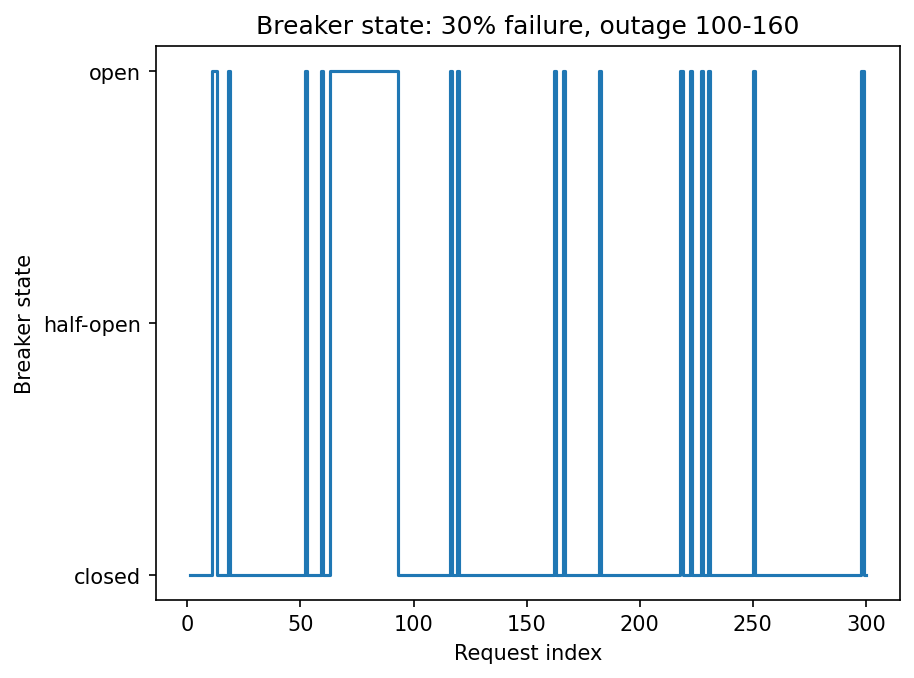

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
from pathlib import Path
from IPython.display import display, Image
from google.colab import files

root = Path('/content/work/HW5_Official_Integrated_Code')
plot = root / 'outputs' / 'student_todo' / 'breaker_state.png'

if plot.exists():
    print("Circuit Breaker Plot found:", plot)
    display(Image(filename=str(plot)))
    files.download(str(plot))
else:
    print("Plot not found. Check the Gateway experiment output.")

---
# Q3 · Mini-Project: Your Own AI Data System (40 points)

The Mini-Project is the additional part of HW5, done in your own notebook or scripts; the assignment PDF has the full specification. Suggested folder:

```
q3/
  data/            raw + processed data (or a download script if the license forbids redistribution)
  ingest.py        validation, cleaning, chunking, versions/freshness for your domain
  system.py        retrieval + grounded answers (+ your production pattern)
  golden.jsonl     >= 30 questions you labelled, including >= 5 unanswerable
  evaluate.ipynb   reuses H.evaluate_retrieval / H.evaluate_answers on golden.jsonl
```

The harness works on any data as long as your golden file uses the same fields (`qid, question, as_of, type,
gold_doc_ids, answer_key, stale_key`) and your chunk ids follow `docid#cN`.

In [36]:
# Q3 Mini-Project: Run the revised evaluation

from pathlib import Path
import subprocess
import sys
import os

project = Path("/content/work/HW5_Official_Integrated_Code")

assert (project / "q3" / "run.py").exists(), \
    "Q3 script was not found."

env = os.environ.copy()
env["PYTHONPATH"] = os.pathsep.join([
    str(project),
    "/content/course/hw5_starter",
    env.get("PYTHONPATH", "")
])

result = subprocess.run(
    [sys.executable, "-m", "q3.run"],
    cwd=str(project),
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Q3 experiment failed.")

# Verify generated outputs
for filename in [
    "q3_ablation.csv",
    "q3_cases.jsonl",
    "q3_failures_to_analyze.json",
    "label_review_sheet.csv",
    "run_info.json"
]:
    path = project / "q3" / "outputs" / filename
    print(filename, "OK" if path.exists() else "MISSING")


{
  "baseline": {
    "n": 44,
    "answerable": 36,
    "unanswerable": 8,
    "retrieval_recall_at3": 0.9166666666666666,
    "citation_precision_answerable": 0.7222222222222222,
    "fact_match_answerable": 0.7222222222222222,
    "strict_source_backed_accuracy": 0.5909090909090909,
    "failure_categories": {
      "wrong_or_missing_citation": 10,
      "unsupported_answer": 8
    }
  },
  "improved": {
    "n": 44,
    "answerable": 36,
    "unanswerable": 8,
    "retrieval_recall_at3": 0.8888888888888888,
    "citation_precision_answerable": 0.8333333333333334,
    "fact_match_answerable": 0.8333333333333334,
    "strict_source_backed_accuracy": 0.8636363636363636,
    "failure_categories": {
      "retrieval_miss_then_abstention": 4,
      "false_abstention_despite_retrieved_evidence": 2
    }
  },
  "cache": {
    "miss": 44,
    "exact": 88
  },
  "failures": 6
}

q3_ablation.csv OK
q3_cases.jsonl OK
q3_failures_to_analyze.json OK
label_review_sheet.csv OK
run_info.json OK


In [37]:

from pathlib import Path
from google.colab import files
import zipfile

project = Path("/content/work/HW5_Official_Integrated_Code")
output_zip = Path("/content/HW5_Final_Experiment_Results.zip")

with zipfile.ZipFile(output_zip, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in ["outputs", "q3/outputs"]:
        directory = project / folder

        if directory.exists():
            for file in directory.rglob("*"):
                if file.is_file():
                    z.write(file, file.relative_to(project))

print("Saved:", output_zip)
print("Size:", output_zip.stat().st_size, "bytes")

files.download(str(output_zip))


Saved: /content/HW5_Final_Experiment_Results.zip
Size: 299581 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [38]:
spark.stop()